# PathSnap: training and testing models 1–2 (Logistic Regression, KNN)

**Owner:** Krishna Jha (Member 2). UE24CS352A Machine Learning hackathon.

This notebook trains and evaluates the models in my part of the plan, against the naive baseline:

| # | Model | Family | Idea |
|---|---|---|---|
| 0 | Nearest-arc baseline | Rule, no training | Always pick the closest road segment |
| 1 | Logistic Regression (unweighted and class-balanced) | Linear / probabilistic | Weighted sum of the features, squashed to a probability |
| 2 | KNN (k = 50) | Instance-based | Score a candidate by the labels of its 50 most similar training candidates |

**Task.** Each GPS fix has about 9 candidate road segments (arcs) within 50 m. Every (fix, candidate) pair is one row, with label 1 if the candidate is the arc the vehicle was really on. A model outputs P(correct) per row, and the highest-scoring candidate is the prediction for that fix.

**Data rules.**
- `train` (80 trips) is used for fitting and cross-validation.
- `student_test` (10 trips) is used only for the final development-stage comparison.
- Evaluator trips are never read.

Every number below is computed by the code in `src/` (the same code as `python -m src.train`), so it is reproducible from the repository.

In [1]:
import os, sys, platform, warnings
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").is_dir():          # notebook started from notebooks/
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import Image, display

from src import evaluate as ev, plot_style as ps, train as tr, compare
from src.config import SEED, N_FOLDS
from src.features import FEATURE_COLUMNS, load_or_build
from src.model_zoo import REGISTRY, make_logreg

# Paths (the environment variables are only for running on another data folder)
DATA_DIR = Path(os.environ.get("PATHSNAP_DATA_DIR", PROJECT_ROOT / "data"))
PROCESSED_DIR = DATA_DIR / "processed"
RESULTS_DIR = Path(os.environ.get("PATHSNAP_RESULTS_DIR", PROJECT_ROOT / "results" / "models"))

# numpy 2.2 + Apple Accelerate emits spurious "divide by zero in matmul" warnings on macOS,
# even for random matrices. They do not affect results.
warnings.filterwarnings("ignore", message=".*encountered in matmul")
import logging
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)   # shared style asks for Segoe UI; falls back to DejaVu Sans
ps.apply_style()
%matplotlib inline
pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.max_columns", 40)

print(f"python {platform.python_version()} | sklearn {sklearn.__version__} | numpy {np.__version__} | pandas {pd.__version__}")
print(f"seed {SEED} | folds {N_FOLDS} | data {DATA_DIR}")

python 3.12.15 | sklearn 1.7.2 | numpy 2.2.6 | pandas 2.3.3
seed 42 | folds 5 | data /Users/krishnajha/Desktop/ml hackathon/pathsnap/data


## 1. Load the candidate and fix tables

Built by KKR's `python -m src.build_dataset`:
- **Candidate table:** one row per (fix, candidate arc), with the label.
- **Fix table:** one row per GPS fix, including fixes that have no candidates.

Top-1 accuracy and the miss rate are computed over the fix table, so a labelled fix with no correct candidate counts as wrong.

Features are added by `src/features.py` and cached in `data/processed/features_<partition>.parquet`.

In [2]:
if not (PROCESSED_DIR / "fixes_train.parquet").exists():
    raise FileNotFoundError("Run `python -m src.build_dataset` first (needs the raw trips in data/).")

cand_tr, fix_tr = tr.load_partition("train", PROCESSED_DIR, DATA_DIR)
cand_te, fix_te = tr.load_partition("student_test", PROCESSED_DIR, DATA_DIR)

summary = pd.DataFrame({
    "trips": [cand_tr.trip_id.nunique(), cand_te.trip_id.nunique()],
    "GPS fixes": [len(fix_tr), len(fix_te)],
    "labelled fixes": [int(fix_tr.fix_valid.sum()), int(fix_te.fix_valid.sum())],
    "candidate rows": [len(cand_tr), len(cand_te)],
    "candidates / fix": [len(cand_tr) / len(fix_tr), len(cand_te) / len(fix_te)],
    "positive rows (label=1)": [cand_tr.label.mean(), cand_te.label.mean()],
    "candidate miss rate": [(fix_tr.fix_valid & ~fix_tr.true_in_cands).sum() / fix_tr.fix_valid.sum(),
                            (fix_te.fix_valid & ~fix_te.true_in_cands).sum() / fix_te.fix_valid.sum()],
}, index=["train", "student_test"])
summary

,trips,GPS fixes,labelled fixes,candidate rows,candidates / fix,positive rows (label=1),candidate miss rate
train,80,208417,187867,1869589,8.9704,0.0991,0.0138
student_test,10,19160,19143,209579,10.9384,0.0913,0.0005


In [3]:
cand_tr[["trip_id", "fix_idx", "arc_id", "dist_m", "cand_rank", "n_cand", "label"] + FEATURE_COLUMNS[5:10]].head(10)

,trip_id,fix_idx,arc_id,dist_m,cand_rank,n_cand,label,heading_diff_deg,cos_heading_diff,has_heading,cos_heading_weighted,speed_mps
0,00000001,0,64973,0.7175,0,3,1,1.3034,0.9997,1,0.9997,43.6294
1,00000001,0,117639,15.0112,1,3,0,178.7650,-0.9998,1,-0.9998,43.6294
2,00000001,0,2641,32.1993,2,3,0,1.4323,0.9997,1,0.9997,43.6294
3,00000001,1,64973,0.2750,0,2,1,0.6839,0.9999,1,0.9999,46.4510
4,00000001,1,117639,15.9516,1,2,0,179.2477,-0.9999,1,-0.9999,46.4510
5,00000001,2,64973,1.8263,0,2,1,3.4973,0.9981,1,0.9981,52.2628
6,00000001,2,117639,13.7915,1,2,0,176.4343,-0.9981,1,-0.9981,52.2628
7,00000001,3,64973,6.1012,0,2,1,2.6112,0.9990,1,0.9990,48.9266
8,00000001,3,117639,9.4509,1,2,0,177.4572,-0.9990,1,-0.9990,48.9266
9,00000001,4,64973,2.6318,0,2,1,0.3974,1.0000,1,1.0000,44.2045


**Class imbalance.** Only about 1 candidate in 9 is correct. Plain accuracy would look high even for a useless model, so the comparison uses **macro F1** (F1 averaged equally over both classes) and the fix-level **Top-1 accuracy**.

## 2. Features

Every feature is computed from the GPS track and the road network only. None of them use `.route`, `true_arc`, `label`, `arc_id` or `trip_id`. Each trip has its own network, so ids carry no meaning across trips.

| Group | Features | Why it helps |
|---|---|---|
| Distance | `dist_m`, `dist_minus_min`, `dist_ratio`, `cand_rank`, `n_cand` | GPS error is small (median ~5 m). Distance relative to the nearest candidate is robust to a GPS bias that shifts every candidate. |
| Direction | `heading_diff_deg`, `cos_heading_diff`, `has_heading`, `cos_heading_weighted` | A two-way road is two arcs at the same distance. Only the direction of travel separates them. Heading is reliable above ~8 m/s, so `cos_heading_weighted` scales it by speed. |
| Kinematics | `speed_mps`, `log_dt_prev`, `log_dt_next` | How much to trust the heading; whether neighbouring fixes are stale (gaps). |
| Arc shape | `log_arc_length`, `t_along`, `is_two_way`, `out_degree_v`, `in_degree_u` | Projections onto an arc end are ambiguous at junctions; topology describes the arc's place in the network. |
| Context | `prev_nearest_link`, `next_nearest_link` | Does the arc continue from / into the nearest arc of the neighbouring fixes? |

In [4]:
lab = cand_tr[cand_tr.fix_valid]
lab[FEATURE_COLUMNS + ["label"]].groupby("label").mean().T.rename(columns={0: "mean | wrong arc", 1: "mean | true arc"})

label,mean | wrong arc,mean | true arc
dist_m,27.1272,6.5204
dist_minus_min,21.8913,0.8200
dist_ratio,7.3609,1.2261
cand_rank,10.4463,0.7416
n_cand,21.0695,9.8728
heading_diff_deg,94.6362,32.0965
cos_heading_diff,-0.0566,0.7191
has_heading,0.9579,0.9661
cos_heading_weighted,-0.0526,0.6586
speed_mps,10.3324,12.4633


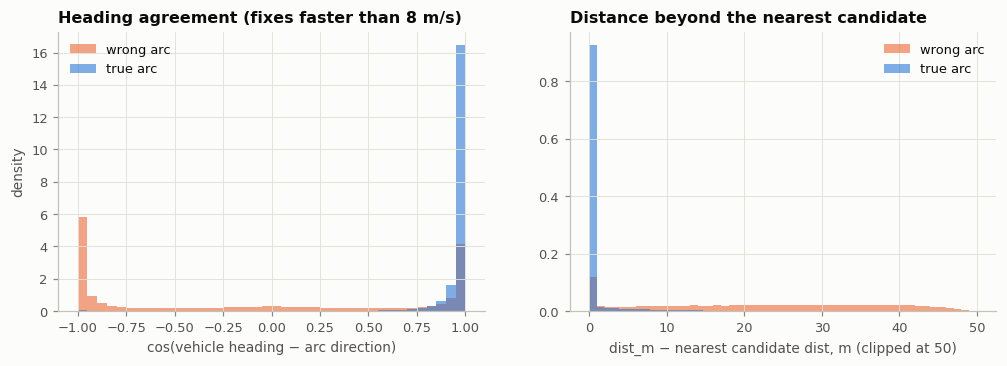

In [5]:
moving = lab[lab.speed_mps > 8]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3))
bins = np.linspace(-1, 1, 41)
for y, c, name in [(0, ps.ORANGE, "wrong arc"), (1, ps.BLUE, "true arc")]:
    axes[0].hist(moving.loc[moving.label == y, "cos_heading_diff"], bins=bins, density=True, alpha=0.6, color=c, label=name)
    axes[1].hist(lab.loc[lab.label == y, "dist_minus_min"].clip(0, 50), bins=50, density=True, alpha=0.6, color=c, label=name)
axes[0].set(title="Heading agreement (fixes faster than 8 m/s)", xlabel="cos(vehicle heading − arc direction)", ylabel="density")
axes[1].set(title="Distance beyond the nearest candidate", xlabel="dist_m − nearest candidate dist, m (clipped at 50)")
for ax in axes: ax.legend()
plt.show()

True arcs cluster at cos ≈ +1, meaning the arc points the way the vehicle moves. The reverse arc of a two-way road sits at −1. This is the information the nearest-arc baseline ignores.

## 3. Evaluation protocol

- **GroupKFold by trip (5 folds) on the 80 train trips.** A whole trip stays in one fold. Consecutive fixes of a trip are nearly identical, so a row-level split would leak and inflate the scores.
- **Preprocessing inside the fold.** Each model is an sklearn `Pipeline`, so `StandardScaler` is fitted on the training fold only.
- After CV, the model is **refit on all 80 train trips** and evaluated **once on student_test**.

| Metric | Level | Meaning |
|---|---|---|
| Accuracy, precision, recall, macro F1, confusion matrix | candidate rows | threshold 0.5 on P(correct) |
| Log loss | candidate rows | quality of the probabilities; the HMM uses them as emissions |
| Top-1 accuracy | fix | is the highest-scored candidate a correct arc? Missing candidates count as wrong. |
| Candidate miss rate | fix | the correct arc is not among the candidates (an upper bound on Top-1) |
| Route continuity | fix sequence | share of consecutive predictions that are the same arc or directly connected |
| Train macro F1 | candidate rows | measured on the training folds; a large gap to CV means overfitting |

In [6]:
folds = pd.DataFrame([{"fold": k, "train trips": len(a), "validation trips": len(b),
                       "validation trip ids": ", ".join(sorted(b))[:60] + "…"}
                      for k, a, b in ev.group_folds(cand_tr, N_FOLDS)])
folds

,fold,train trips,validation trips,validation trip ids
0,0,64,16,"00000004, 00000012, 00000018, 00000025, 000000..."
1,1,64,16,"00000005, 00000019, 00000022, 00000024, 000000..."
2,2,64,16,"00000006, 00000011, 00000013, 00000020, 000000..."
3,3,64,16,"00000002, 00000008, 00000014, 00000021, 000000..."
4,4,64,16,"00000001, 00000003, 00000010, 00000016, 000000..."


## 4. Baseline: nearest arc

The baseline scores 1 for the nearest candidate and 0 for the rest, with no learning. Its scores are hard 0/1 values, so log loss is not meaningful (N/A).

In [7]:
TRAIN, TEST = (cand_tr, fix_tr), (cand_te, fix_te)
rows = {}
rows["baseline"] = tr.run_model("baseline", TRAIN, TEST, RESULTS_DIR, N_FOLDS, SEED, quick=False)


=== baseline (Rule (no training)) ===


  fold 0: macro F1 0.7529  Top-1 0.5386  log loss nan


  fold 1: macro F1 0.7918  Top-1 0.6264  log loss nan


  fold 2: macro F1 0.7813  Top-1 0.5942  log loss nan


  fold 3: macro F1 0.7021  Top-1 0.4751  log loss nan


  fold 4: macro F1 0.7601  Top-1 0.5581  log loss nan


  student_test: macro F1 0.7459  Top-1 0.5381  log loss nan  continuity 0.8210


## 5. Model 1: Logistic Regression

**Why it suits the problem:**
- It's a linear, probabilistic model. Its probabilities are naturally calibrated, which matters because the HMM uses them as emission scores.
- Its weights are interpretable, so we can see which clues it relies on.

**Configuration:** `StandardScaler` → `LogisticRegression(C=1, max_iter=2000)`.

**Two versions** (as required by the team plan):
- `logreg`: unweighted
- `logreg_balanced`: `class_weight="balanced"`. This up-weights the rare positive rows, which usually raises recall but pushes probabilities upwards (worse log loss).

**Loss:** binary cross-entropy (log loss) with L2 regularisation. It is fitted by a solver, not epochs, so there is no loss curve.

**Limits:**
- The decision boundary is linear in the features, so interactions must be supplied by hand. For example, `cos_heading_weighted` encodes "heading matters only when the car is moving".

In [8]:
rows["logreg"] = tr.run_model("logreg", TRAIN, TEST, RESULTS_DIR, N_FOLDS, SEED, quick=False)
rows["logreg_balanced"] = tr.run_model("logreg_balanced", TRAIN, TEST, RESULTS_DIR, N_FOLDS, SEED, quick=False)


=== logreg (Linear / probabilistic) ===


  fold 0: macro F1 0.9001  Top-1 0.8592  log loss 0.0924


  fold 1: macro F1 0.8907  Top-1 0.8620  log loss 0.1065


  fold 2: macro F1 0.8989  Top-1 0.8430  log loss 0.1015


  fold 3: macro F1 0.8530  Top-1 0.7672  log loss 0.1538


  fold 4: macro F1 0.8871  Top-1 0.8495  log loss 0.0938


... (4 outputs left out)

  fold 2: macro F1 0.8284  Top-1 0.8323  log loss 0.1777


  fold 3: macro F1 0.7800  Top-1 0.7411  log loss 0.2998


  fold 4: macro F1 0.8097  Top-1 0.8066  log loss 0.1872


  student_test: macro F1 0.8159  Top-1 0.8134  log loss 0.1924  continuity 0.9466


In [9]:
show = ["fold", "macro_f1", "top1", "log_loss", "precision", "recall", "route_continuity", "train_macro_f1",
        "train_time_s", "infer_ms_per_1k_fixes"]
pd.read_csv(RESULTS_DIR / "logreg" / "cv_folds.csv")[show]

,fold,macro_f1,top1,log_loss,precision,recall,route_continuity,train_macro_f1,train_time_s,infer_ms_per_1k_fixes
0,0,0.9001,0.8592,0.0924,0.8176,0.8174,0.9418,0.8810,0.7947,0.9315
1,1,0.8907,0.8620,0.1065,0.8279,0.7816,0.9359,0.8820,0.7919,0.3348
2,2,0.8989,0.8430,0.1015,0.8290,0.8024,0.9468,0.8844,0.8170,0.4731
3,3,0.8530,0.7672,0.1538,0.7534,0.7339,0.9673,0.8936,0.6915,0.2451
4,4,0.8871,0.8495,0.0938,0.8063,0.7808,0.9234,0.8816,0.6661,0.3522


### What did Logistic Regression learn?

The model is refit on all train trips and its standardised coefficients are shown below. A positive weight means a larger feature value makes the candidate more likely to be correct. The features are standardised, so the sizes are comparable.

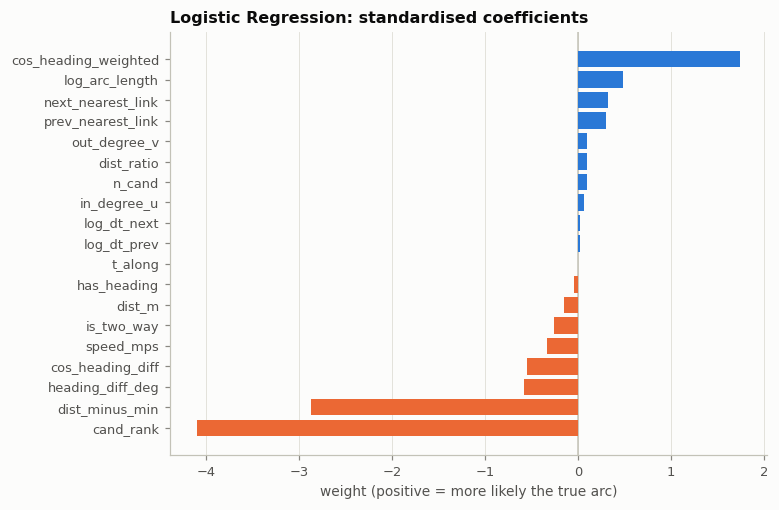

In [10]:
spec = REGISTRY["logreg"]
train_rows = ev.training_rows(cand_tr)
lr = make_logreg(**spec.params).fit(train_rows[FEATURE_COLUMNS].to_numpy(float), train_rows["label"].to_numpy())
coef = pd.Series(lr.named_steps["clf"].coef_[0], index=FEATURE_COLUMNS).sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(coef.index, coef.values, color=[ps.BLUE if v > 0 else ps.ORANGE for v in coef.values], zorder=3)
ax.axvline(0, color=ps.BASELINE, lw=1)
ax.set(title="Logistic Regression: standardised coefficients", xlabel="weight (positive = more likely the true arc)")
ax.grid(axis="y", visible=False)
plt.show()

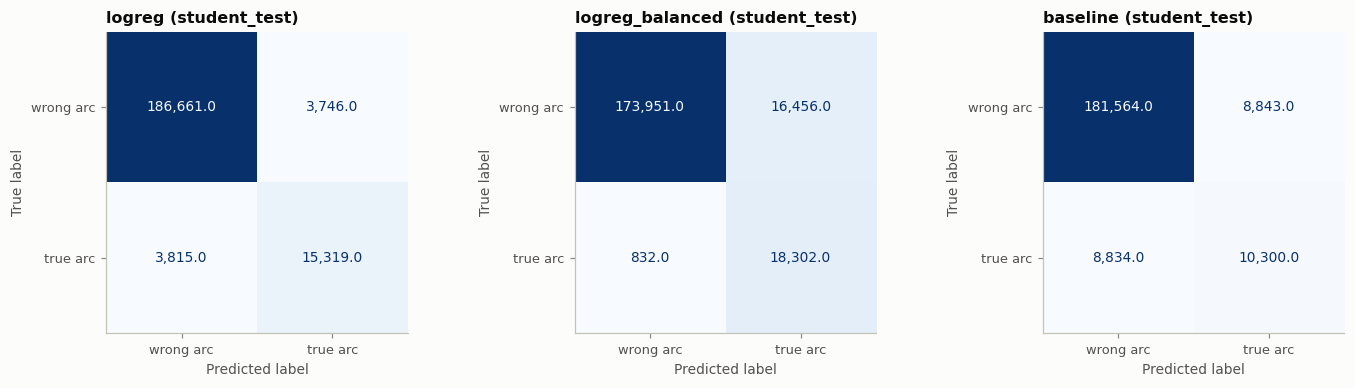

In [11]:
from sklearn.metrics import ConfusionMatrixDisplay
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, name in zip(axes, ["logreg", "logreg_balanced", "baseline"]):
    m = pd.read_json(RESULTS_DIR / name / "student_test_metrics.json", typ="series")
    cm = np.array([[m.tn, m.fp], [m.fn, m.tp]])
    ConfusionMatrixDisplay(cm, display_labels=["wrong arc", "true arc"]).plot(ax=ax, colorbar=False, cmap="Blues", values_format=",")
    ax.set_title(f"{name} (student_test)")
    ax.grid(False)
plt.tight_layout(); plt.show()

## 6. Model 2: KNN

**Why it suits the problem:**
- It makes no assumption about the shape of the decision boundary.
- Every feature is geometric, so a candidate that *looks like* past correct candidates is probably correct, even in a different country's network.

**Configuration:** `StandardScaler` → `KNeighborsClassifier(k=50, weights="uniform")`.
- **Scaling** is essential. Without it, metre-valued features would dominate the distance.
- **k=50** gives probabilities in steps of 0.02, and averaging over many neighbours smooths out label noise.
- **Uniform weights:** with distance weights, every training point is its own nearest neighbour, which makes training-set scores meaningless.

**Training sample:** KNN stores the training set and searches it at prediction time. To keep CV tractable, it trains on a **300k-row stratified sample** of the labelled rows, and the report must say so.

**Limits:**
- Slow inference.
- Probabilities are coarse.
- Sensitive to irrelevant features.

In [12]:
rows["knn"] = tr.run_model("knn", TRAIN, TEST, RESULTS_DIR, N_FOLDS, SEED, quick=False)
pd.read_csv(RESULTS_DIR / "knn" / "cv_folds.csv")[show]


=== knn (Instance-based) ===


  fold 0: macro F1 0.8998  Top-1 0.8351  log loss 0.0937


  fold 1: macro F1 0.8971  Top-1 0.8415  log loss 0.1085


  fold 2: macro F1 0.8947  Top-1 0.8168  log loss 0.1060


  fold 3: macro F1 0.8584  Top-1 0.7559  log loss 0.1745


  fold 4: macro F1 0.8936  Top-1 0.8294  log loss 0.0976


  student_test: macro F1 0.8953  Top-1 0.8287  log loss 0.0928  continuity 0.9356


,fold,macro_f1,top1,log_loss,precision,recall,route_continuity,train_macro_f1,train_time_s,infer_ms_per_1k_fixes
0,0,0.8998,0.8351,0.0937,0.8328,0.8012,0.9376,0.8931,0.0317,946.5430
1,1,0.8971,0.8415,0.1085,0.8186,0.8134,0.9323,0.8949,0.0234,804.4150
2,2,0.8947,0.8168,0.1060,0.8169,0.7992,0.9467,0.8950,0.0238,871.1655
3,3,0.8584,0.7559,0.1745,0.7736,0.7324,0.9583,0.9082,0.0177,651.1089
4,4,0.8936,0.8294,0.0976,0.8262,0.7850,0.9140,0.8967,0.0234,949.8771


### Choice of k (train partition only)

This is a small sensitivity check: 3-fold GroupKFold on the train trips with a 100k-row training sample per fold. Student-test data is not used. It shows how Top-1 and log loss react to k.

In [13]:
from src.model_zoo import make_knn
sens = []
for k in [10, 25, 50, 100]:
    f = ev.group_cv(make_knn, {"n_neighbors": k}, cand_tr, fix_tr, FEATURE_COLUMNS, n_folds=3,
                    max_train_rows=100_000, verbose=False)
    sens.append({"k": k, "cv_top1": f.top1.mean(), "cv_macro_f1": f.macro_f1.mean(), "cv_log_loss": f.log_loss.mean(),
                 "train_macro_f1": f.train_macro_f1.mean()})
pd.DataFrame(sens)

,k,cv_top1,cv_macro_f1,cv_log_loss,train_macro_f1
0,10,0.7983,0.8787,0.1692,0.8995
1,25,0.7982,0.8782,0.1344,0.8907
2,50,0.7954,0.8771,0.1232,0.8853
3,100,0.7907,0.8726,0.1186,0.8788


## 7. Comparison

All models were evaluated with the same features, folds and metrics. The table below is `results/models/model_comparison.csv`; models added by the rest of the team appear here too after they run `python -m src.train`.

In [14]:
table = tr.update_comparison(list(rows.values()), RESULTS_DIR / "model_comparison.csv")
view = table.set_index("model")[[
    "family", "cv_macro_f1_mean", "cv_macro_f1_std", "cv_top1_mean", "cv_train_macro_f1_mean",
    "st_macro_f1", "st_top1", "st_precision", "st_recall", "st_log_loss", "st_route_continuity",
    "st_candidate_miss_rate", "train_time_s", "infer_ms_per_1k_fixes"]]
view

,family,cv_macro_f1_mean,cv_macro_f1_std,cv_top1_mean,cv_train_macro_f1_mean,st_macro_f1,st_top1,st_precision,st_recall,st_log_loss,st_route_continuity,st_candidate_miss_rate,train_time_s,infer_ms_per_1k_fixes
model,,,,,,,,,,,,,,
baseline,Rule (no training),0.7576,0.0348,0.5585,NaN,0.7459,0.5381,0.5381,0.5383,NaN,0.8210,0.0005,0.0000,NaN
logreg,Linear / probabilistic,0.8860,0.0192,0.8362,0.8845,0.8911,0.8440,0.8035,0.8006,0.0906,0.9445,0.0005,0.9377,0.8668
logreg_balanced,Linear / probabilistic,0.8151,0.0219,0.8106,0.8140,0.8159,0.8134,0.5266,0.9565,0.1924,0.9466,0.0005,1.7187,0.5342
knn,Instance-based,0.8887,0.0171,0.8157,0.8976,0.8953,0.8287,0.8172,0.8020,0.0928,0.9356,0.0005,0.0234,932.5141


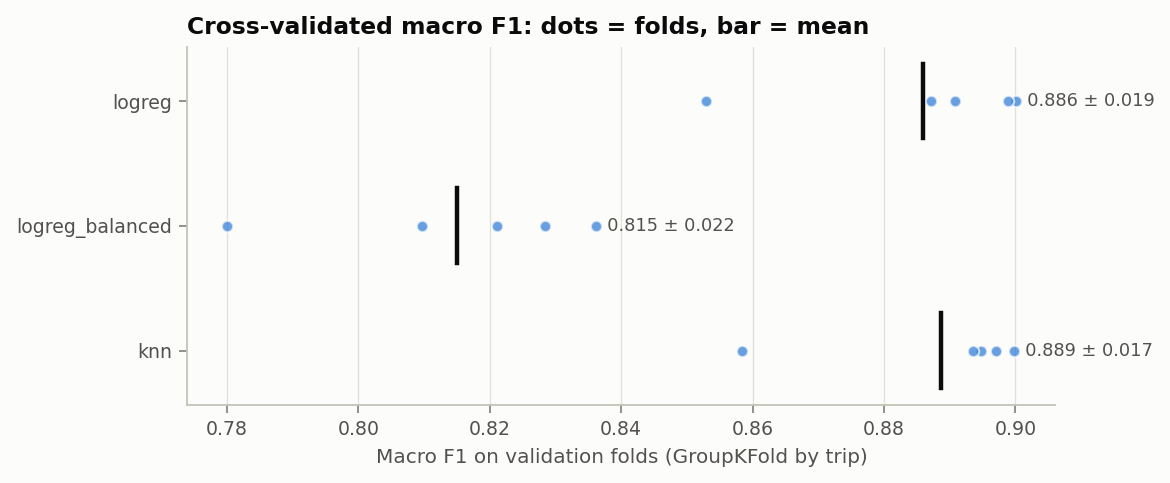

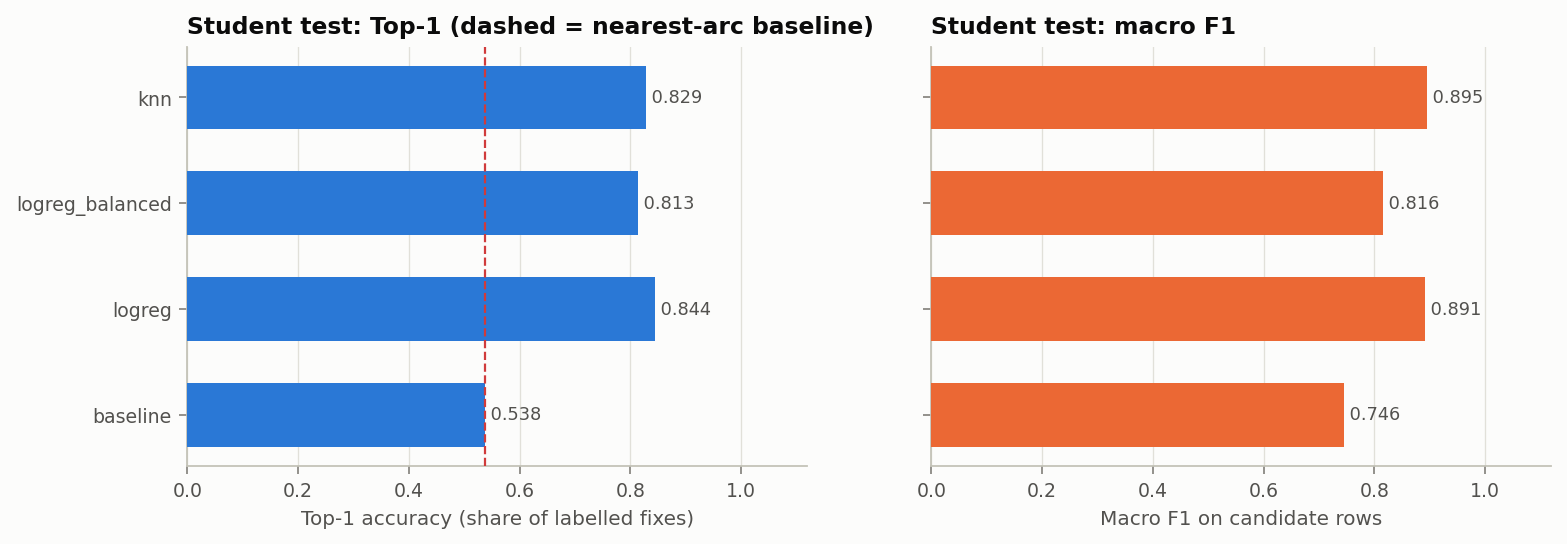

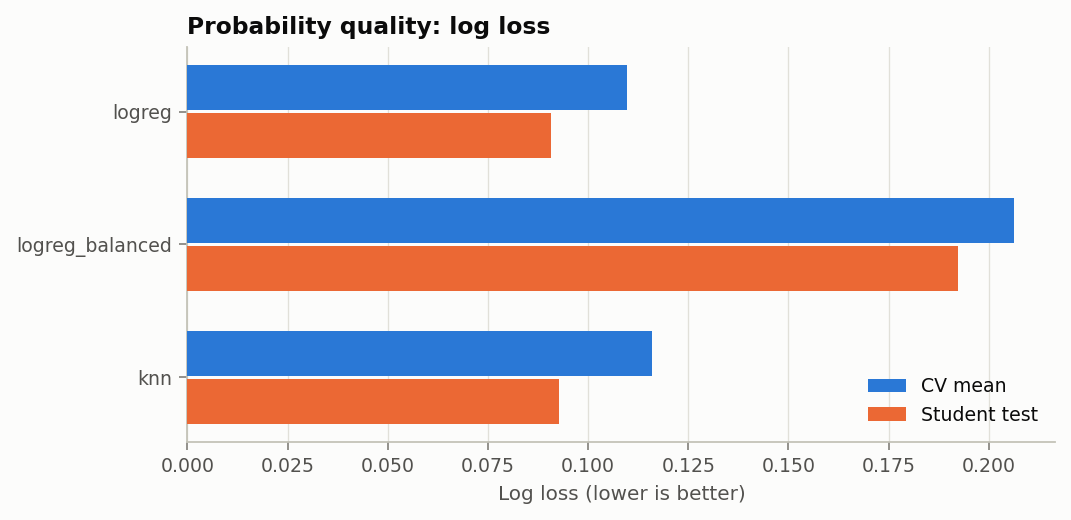

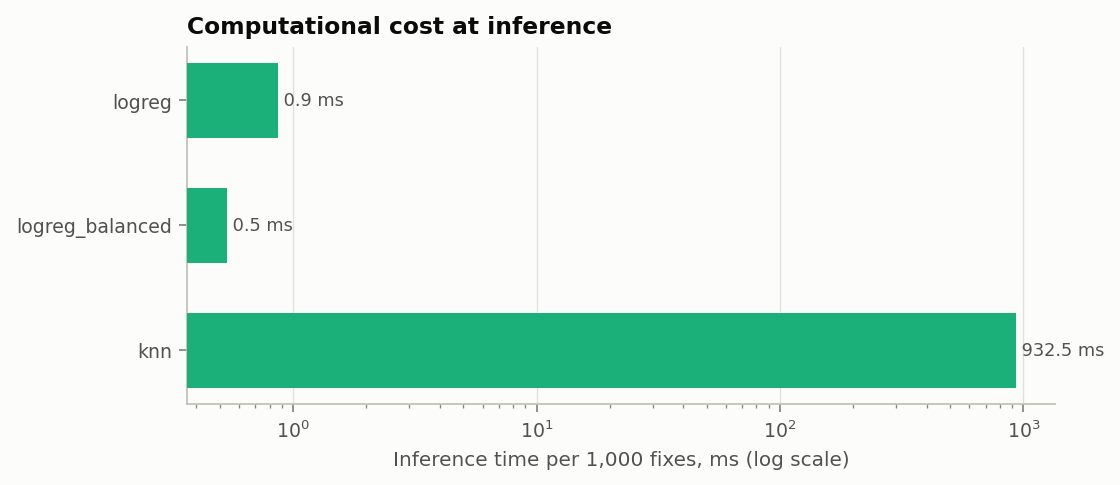

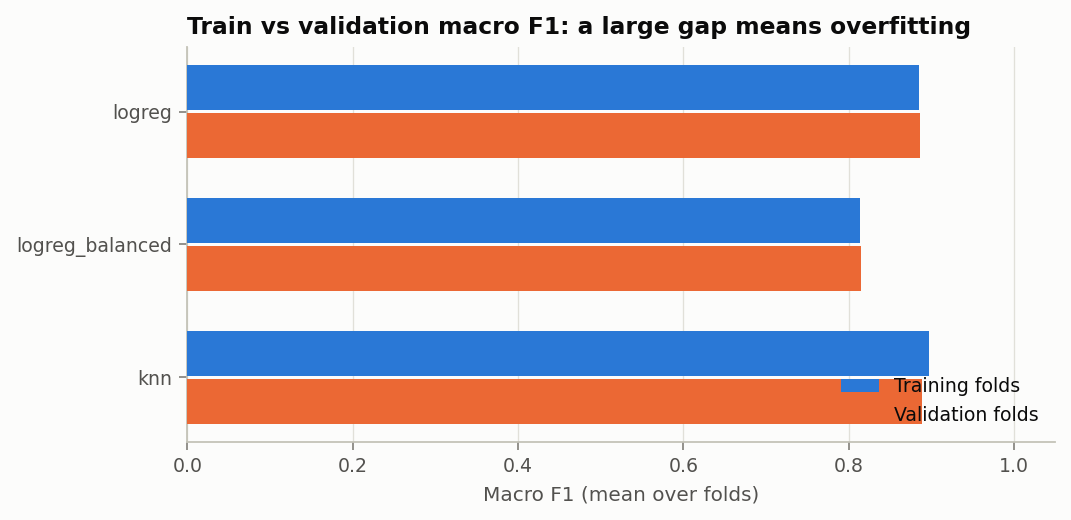

In [15]:
for p in compare.make_all(RESULTS_DIR):
    display(Image(filename=str(p)))

## 8. Summary

The numbers below are generated from the results table. There is no hand-written result.

In [16]:
t = table.set_index("model")
base = t.loc["baseline", "st_top1"]
models = t.drop(index="baseline")
best_top1 = models["st_top1"].idxmax()
best_ll = models["st_log_loss"].idxmin()
print(f"Nearest-arc baseline, student_test Top-1: {base:.4f}")
for m, r in models.iterrows():
    print(f"{m:>16}: Top-1 {r.st_top1:.4f} ({(r.st_top1 - base) * 100:+.1f} pts vs baseline) | "
          f"macro F1 {r.st_macro_f1:.4f} | log loss {r.st_log_loss:.4f} | "
          f"train−CV F1 gap {r.cv_train_macro_f1_mean - r.cv_macro_f1_mean:+.4f} | "
          f"{r.infer_ms_per_1k_fixes:.1f} ms / 1k fixes")
print(f"\nBest Top-1: {best_top1} | best probability quality (lowest log loss): {best_ll}")
print(f"Upper bound on Top-1 from candidate misses: {1 - t.loc['baseline', 'st_candidate_miss_rate']:.4f}")

Nearest-arc baseline, student_test Top-1: 0.5381
          logreg: Top-1 0.8440 (+30.6 pts vs baseline) | macro F1 0.8911 | log loss 0.0906 | train−CV F1 gap -0.0015 | 0.9 ms / 1k fixes
 logreg_balanced: Top-1 0.8134 (+27.5 pts vs baseline) | macro F1 0.8159 | log loss 0.1924 | train−CV F1 gap -0.0011 | 0.5 ms / 1k fixes
             knn: Top-1 0.8287 (+29.1 pts vs baseline) | macro F1 0.8953 | log loss 0.0928 | train−CV F1 gap +0.0088 | 932.5 ms / 1k fixes

Best Top-1: logreg | best probability quality (lowest log loss): logreg
Upper bound on Top-1 from candidate misses: 0.9995


**How to read this**

- **Top-1 vs baseline:** how much the features, especially direction, add over picking the nearest arc.
- **Log loss:** which model gives the most trustworthy probabilities for the HMM. Unweighted Logistic Regression is expected to be better calibrated than the class-balanced version.
- **CV-vs-train gap:** a large positive gap means overfitting; low scores on both mean underfitting.
- **Inference time:** the live demo has to answer within a few seconds per trip.

The final model is chosen across all 6 models (team decision, primary metric agreed with Joshua). These two models are the linear and instance-based entries in that comparison.